In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
df = pd.read_csv("heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
print("Shape:", df.shape)   # (rows, columns)
df.info()                   # each column's type + non-null count

Shape: (1025, 14)
<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [4]:
df['target'].value_counts()                 # raw counts
df['target'].value_counts(normalize=True)   # as proportions

target
1    0.513171
0    0.486829
Name: proportion, dtype: float64

In [5]:
df.isnull().sum()        # missing values per column
df.duplicated().sum()    # how many duplicate rows

np.int64(723)

In [6]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [7]:
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)   # expect ~ (302, 14)
print("Duplicates now:", df.duplicated().sum())        # should be 0

Shape after removing duplicates: (302, 14)
Duplicates now: 0


In [8]:
print("Resting BP = 0:  ", (df['trestbps'] == 0).sum())
print("Cholesterol = 0: ", (df['chol'] == 0).sum())

Resting BP = 0:   0
Cholesterol = 0:  0


In [9]:
df[df['trestbps'] == 0]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target


In [10]:
df = df[df['trestbps'] != 0]
print("Shape after removing impossible BP:", df.shape)

Shape after removing impossible BP: (302, 14)


In [11]:
numeric_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

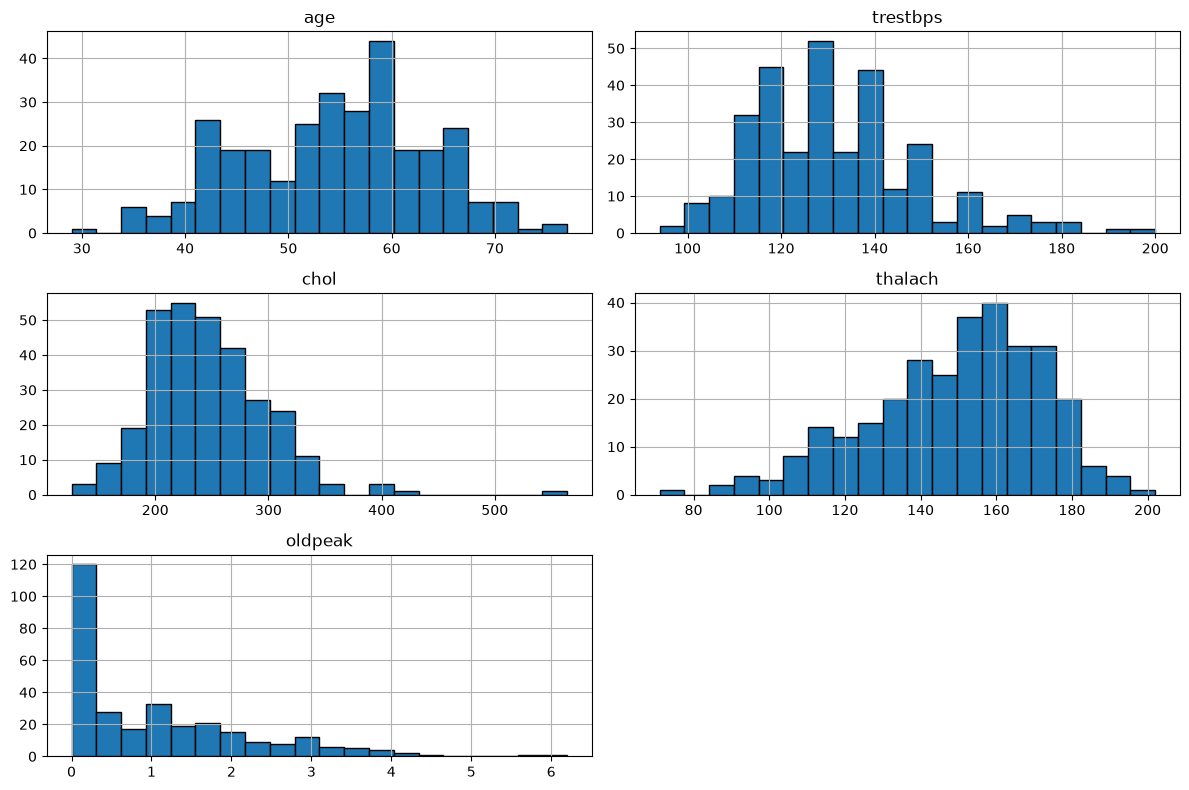

In [12]:
df[numeric_features].hist(figsize=(12, 8), bins=20, edgecolor='black')
plt.tight_layout()
plt.show()

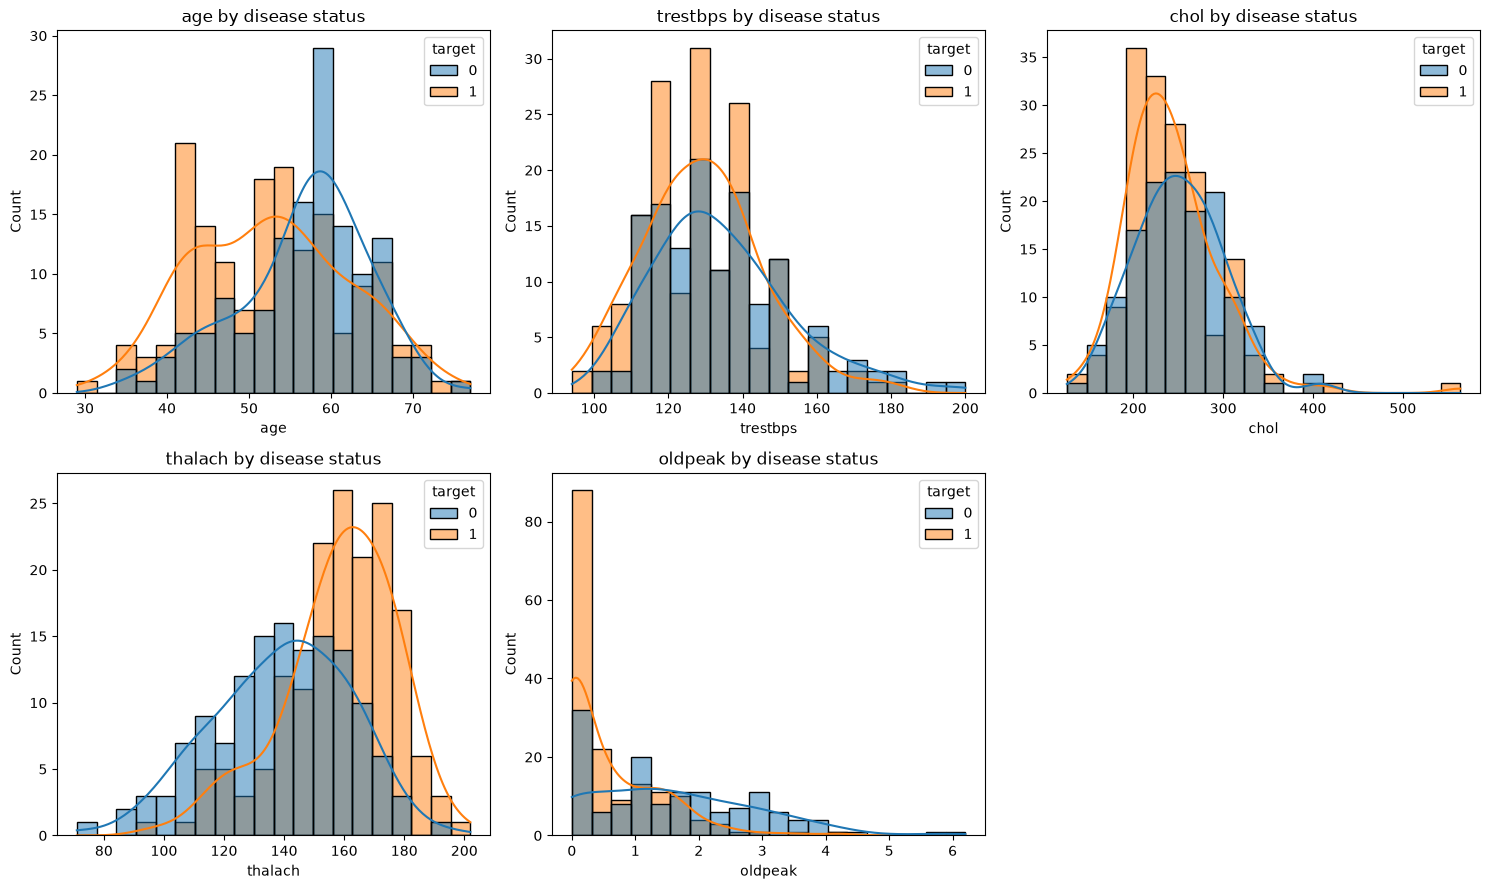

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    sns.histplot(data=df, x=col, hue='target', kde=True, ax=axes[i], bins=20)
    axes[i].set_title(f'{col} by disease status')

axes[5].axis('off')   # hide the empty 6th panel
plt.tight_layout()
plt.show()

In [14]:
df.groupby('target')[['age', 'thalach', 'oldpeak', 'ca', 'exang', 'chol']].mean()

,age,thalach,oldpeak,ca,exang,chol
target,,,,,,
0,56.601449,139.101449,1.585507,1.166667,0.550725,251.086957
1,52.585366,158.378049,0.586585,0.341463,0.140244,242.640244


In [15]:
df['target'] = 1 - df['target']

In [16]:
df.groupby('target')[['thalach', 'oldpeak', 'ca', 'exang']].mean()

,thalach,oldpeak,ca,exang
target,,,,
0,158.378049,0.586585,0.341463,0.140244
1,139.101449,1.585507,1.166667,0.550725


In [17]:
df['target'].value_counts(normalize=True)

target
0    0.543046
1    0.456954
Name: proportion, dtype: float64

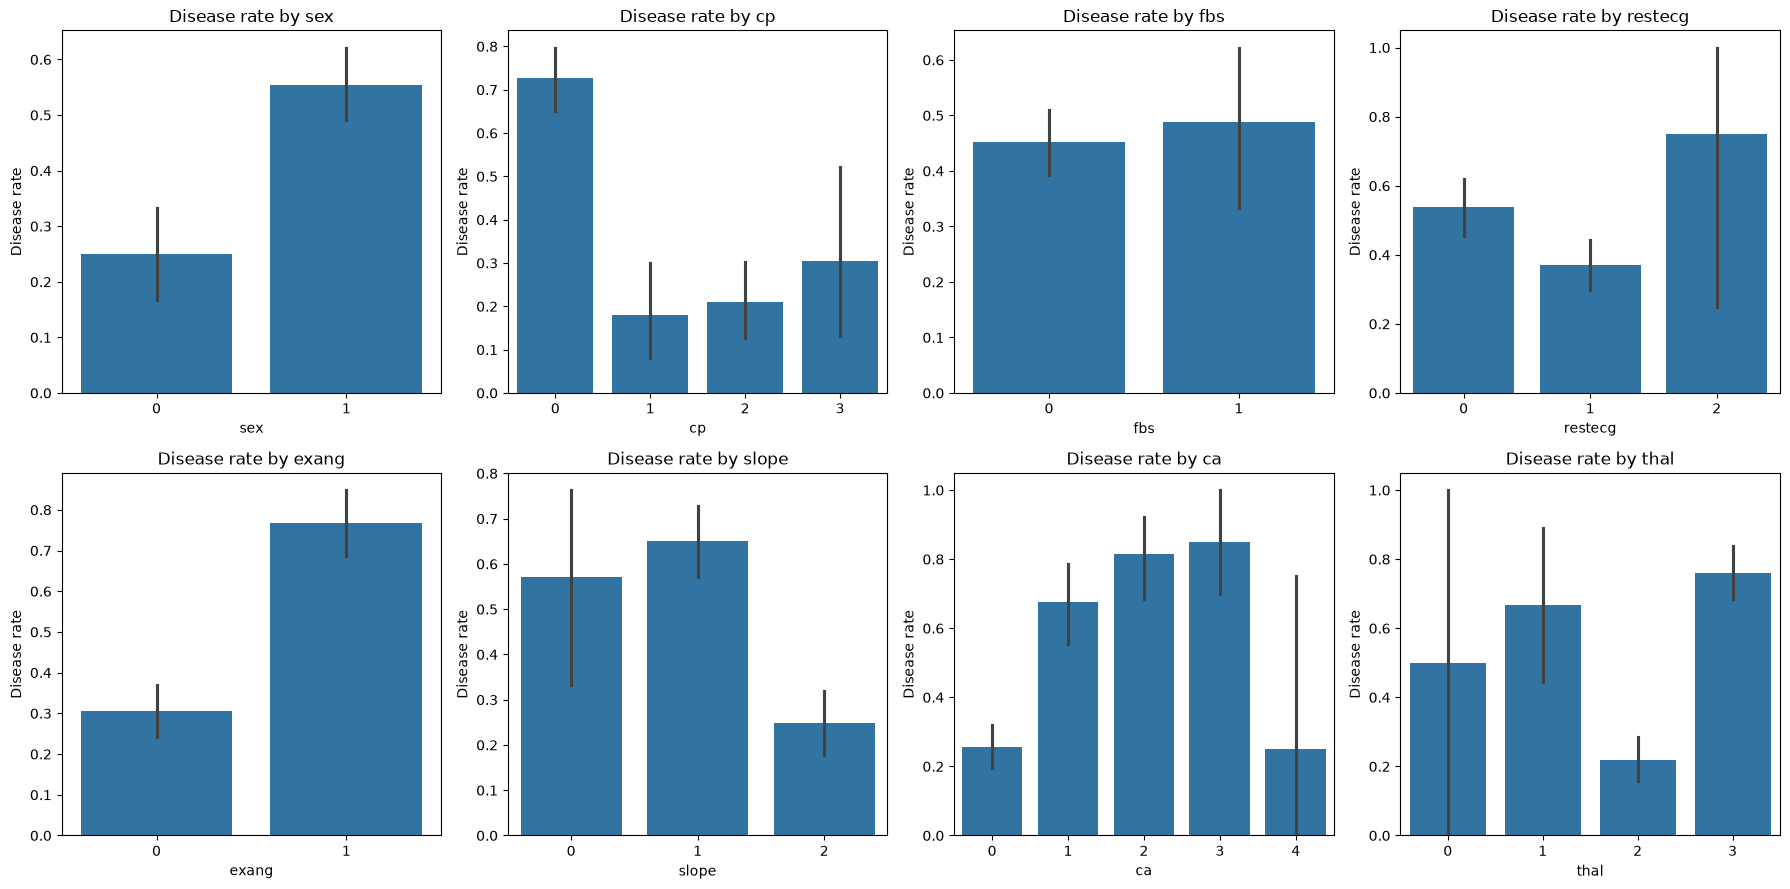

In [18]:
categorical_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, col in enumerate(categorical_features):
    sns.barplot(data=df, x=col, y='target', ax=axes[i])
    axes[i].set_title(f'Disease rate by {col}')
    axes[i].set_ylabel('Disease rate')

plt.tight_layout()
plt.show()

In [19]:
df.corr()['target'].sort_values(ascending=False)

target      1.000000
exang       0.435601
oldpeak     0.429146
ca          0.408992
thal        0.343101
sex         0.283609
age         0.221476
trestbps    0.146269
chol        0.081437
fbs         0.026826
restecg    -0.134874
slope      -0.343940
thalach    -0.419955
cp         -0.432080
Name: target, dtype: float64

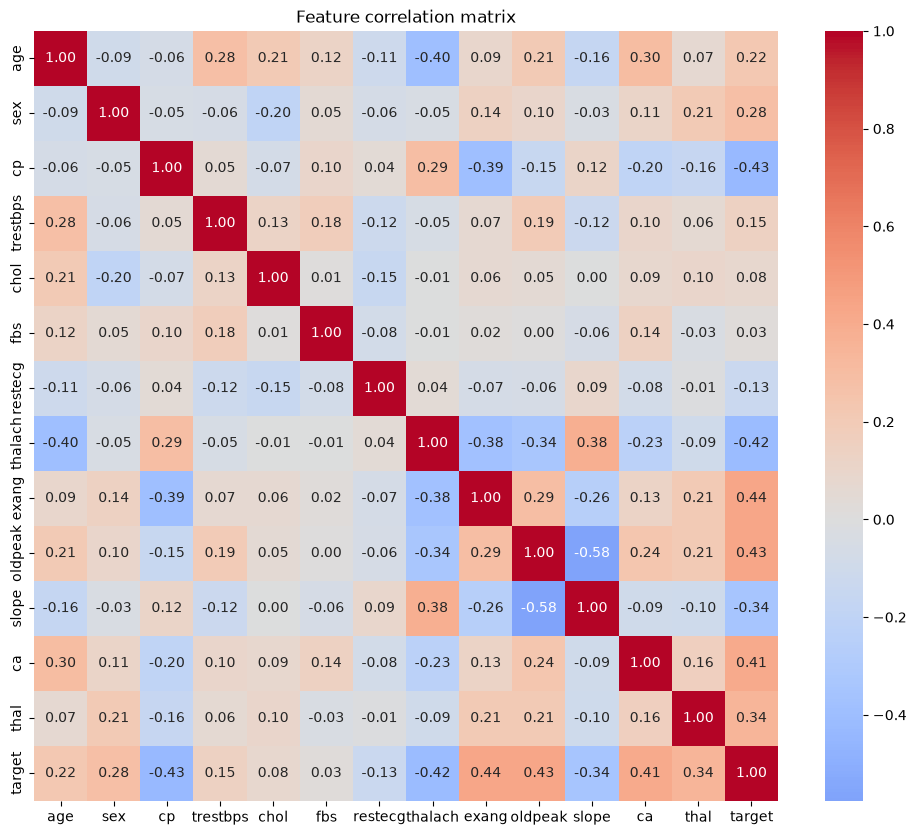

In [20]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Feature correlation matrix')
plt.show()

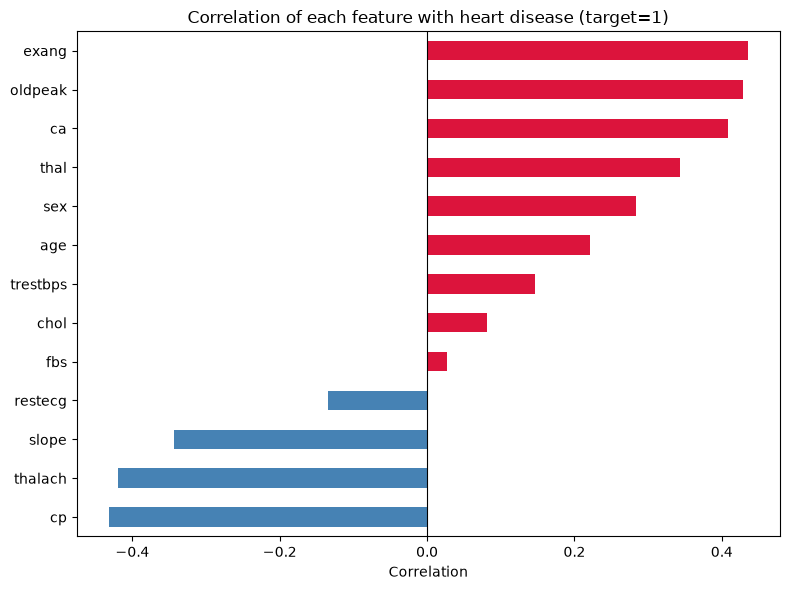

In [21]:
target_corr = df.corr()['target'].drop('target').sort_values()

plt.figure(figsize=(8, 6))
colors = ['crimson' if x > 0 else 'steelblue' for x in target_corr]
target_corr.plot(kind='barh', color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlation of each feature with heart disease (target=1)')
plt.xlabel('Correlation')
plt.tight_layout()
plt.show()

## Modeling

With the data cleaned (duplicates removed, labels corrected) and explored, we build the
predictive models. Because this is framed as a **medical screening** problem, we value
**recall** (catching patients who truly have disease) over raw accuracy — a missed case is
far more costly than a false alarm.

Workflow: train/test split -> scaling -> logistic regression baseline -> random forest ->
cross-validation for an honest estimate -> decision-threshold tuning for recall ->
feature-importance interpretation.

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('target', axis=1)
y = df['target']

# Stratified split keeps the same class balance in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Scale features (fit on train only, so no test information leaks in)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (241, 13)  Test: (61, 13)


In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             roc_auc_score, confusion_matrix)

logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train_scaled, y_train)

lr_pred = logreg.predict(X_test_scaled)
lr_proba = logreg.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression")
print("Accuracy :", round(accuracy_score(y_test, lr_pred), 3))
print("Recall   :", round(recall_score(y_test, lr_pred), 3))
print("Precision:", round(precision_score(y_test, lr_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, lr_proba), 3))
print("Confusion matrix:\n", confusion_matrix(y_test, lr_pred))

Logistic Regression
Accuracy : 0.787
Recall   : 0.75
Precision: 0.778
ROC-AUC  : 0.89
Confusion matrix:
 [[27  6]
 [ 7 21]]


In [24]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(X_train, y_train)   # tree models don't need scaling

rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]

print("Random Forest")
print("Accuracy :", round(accuracy_score(y_test, rf_pred), 3))
print("Recall   :", round(recall_score(y_test, rf_pred), 3))
print("Precision:", round(precision_score(y_test, rf_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, rf_proba), 3))
print("Confusion matrix:\n", confusion_matrix(y_test, rf_pred))

Random Forest
Accuracy : 0.836
Recall   : 0.857
Precision: 0.8
ROC-AUC  : 0.884
Confusion matrix:
 [[27  6]
 [ 4 24]]


### Cross-validation: an honest performance estimate

A single train/test split on ~300 rows is noisy. To report a number we can trust, we use
5-fold stratified cross-validation and report the mean ROC-AUC **and its spread**, scaling
inside each fold so no information leaks across folds.

In [25]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Pipeline scales within each fold's training data only
lr_pipe = make_pipeline(StandardScaler(),
                        LogisticRegression(max_iter=1000, random_state=42))
lr_cv = cross_val_score(lr_pipe, X, y, cv=cv, scoring='roc_auc')
rf_cv = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=42),
                        X, y, cv=cv, scoring='roc_auc')

print(f"Logistic Regression CV ROC-AUC: {lr_cv.mean():.3f} +/- {lr_cv.std():.3f}")
print(f"Random Forest       CV ROC-AUC: {rf_cv.mean():.3f} +/- {rf_cv.std():.3f}")

Logistic Regression CV ROC-AUC: 0.905 +/- 0.018
Random Forest       CV ROC-AUC: 0.908 +/- 0.016


### Tuning the decision threshold for recall

By default a classifier flags disease when the predicted probability >= 0.50. In screening we
would rather catch more true cases even at the cost of more false alarms, so we lower the
threshold and watch how the confusion matrix shifts. We tune the interpretable logistic
regression model.

In [26]:
print("threshold  recall  precision  missed(FN)  false_alarms(FP)")
for t in [0.50, 0.40, 0.35, 0.30, 0.25]:
    pred_t = (lr_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_t).ravel()
    print(f"   {t:.2f}      {recall_score(y_test, pred_t):.3f}     "
          f"{precision_score(y_test, pred_t):.3f}        {fn}             {fp}")

# Chosen operating point: 0.30 prioritises recall for a screening use-case
chosen = 0.30
final_pred = (lr_proba >= chosen).astype(int)
print(f"\nChosen threshold = {chosen}")
print("Confusion matrix at chosen threshold:\n", confusion_matrix(y_test, final_pred))

threshold  recall  precision  missed(FN)  false_alarms(FP)
   0.50      0.750     0.778        7             6
   0.40      0.821     0.767        5             7
   0.35      0.857     0.774        4             7
   0.30      0.929     0.743        2             9
   0.25      0.929     0.703        2             11

Chosen threshold = 0.3
Confusion matrix at chosen threshold:
 [[24  9]
 [ 2 26]]


### Feature importance: does the model rely on clinically meaningful signals?

We inspect what drives predictions using random-forest impurity importances. Agreement with
the logistic-regression coefficients, the exploratory analysis, and known cardiology is a
good sanity check that the model learned real signal rather than noise.

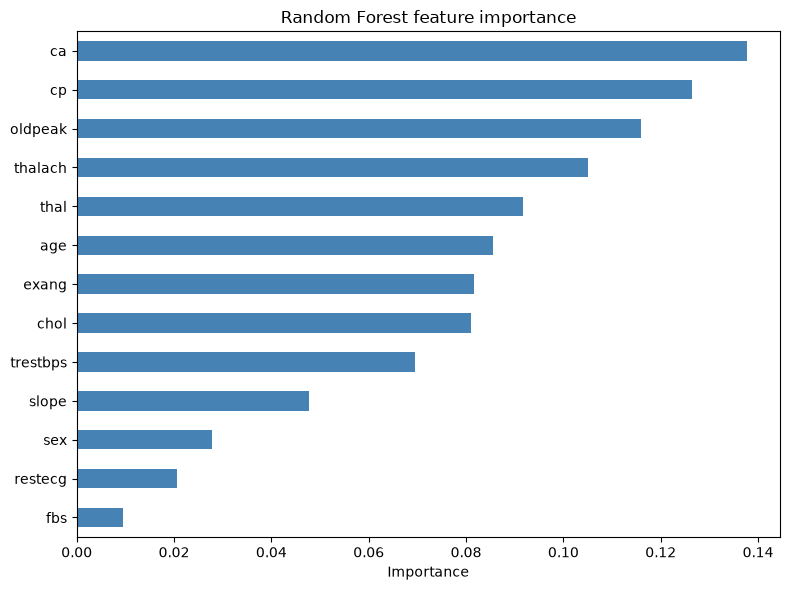

ca          0.137622
cp          0.126399
oldpeak     0.115965
thalach     0.104957
thal        0.091774
age         0.085540
exang       0.081640
chol        0.081075
trestbps    0.069482
slope       0.047659
sex         0.027763
restecg     0.020688
fbs         0.009436
dtype: float64

In [27]:
rf_importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 6))
rf_importance.plot(kind='barh', color='steelblue')
plt.title('Random Forest feature importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

rf_importance.sort_values(ascending=False)